# Thực hành Data Science – Potential Compass

**Dữ liệu ở đây là giả lập.** Mỗi em ảo có một *nhóm thích thật* do máy đặt sẵn.
Ngoài đời không ai biết nhóm đó, nên app chưa thể huấn luyện mô hình phân loại.

Cách chạy: mở [Google Colab](https://colab.research.google.com) → *File › Upload notebook* → chọn file này → *Runtime › Run all*. Không cần cài gì.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, silhouette_score

# 8 nhóm lĩnh vực của app
NHOM = ["KhoaHoc", "KyThuat", "NongLam", "KinhDoanh", "SucKhoe", "NgheThuat", "XaHoi", "TheChat"]
rng = np.random.default_rng(2026)

## Phần 1 – Tạo học sinh giả lập

Mỗi em có 8 điểm nhóm (0–100). Nhóm thích thật được cộng thêm `DO_RO` điểm. Em đọc hiểu kém thì điểm nhiễu hơn.
Công thức này đơn giản hơn nhiều so với cách chấm điểm thật của app.

In [2]:
DO_RO = 32  # nhóm thích thật được cộng thêm bao nhiêu điểm

def tao_hoc_sinh(so_em):
    thich_that = rng.integers(0, 8, so_em)            # ngoài đời KHÔNG có cột này
    do_nhieu = rng.uniform(10, 25, so_em)             # mỗi em nhiễu một mức khác nhau
    diem = 50 + rng.normal(0, 1, (so_em, 8)) * do_nhieu[:, None]
    diem[np.arange(so_em), thich_that] += DO_RO
    df = pd.DataFrame(np.clip(diem, 0, 100).round(), columns=NHOM)
    df["thich_that"] = [NHOM[i] for i in thich_that]
    return df

hs = tao_hoc_sinh(300)
hs.head()

,KhoaHoc,KyThuat,NongLam,KinhDoanh,SucKhoe,NgheThuat,XaHoi,TheChat,thich_that
0,85.0,67.0,29.0,59.0,78.0,48.0,85.0,10.0,XaHoi
1,37.0,55.0,78.0,57.0,61.0,47.0,28.0,53.0,KyThuat
2,70.0,32.0,51.0,52.0,47.0,35.0,31.0,50.0,KhoaHoc
3,67.0,28.0,41.0,48.0,48.0,74.0,76.0,55.0,NgheThuat
4,30.0,12.0,79.0,80.0,54.0,4.0,22.0,52.0,NongLam


## Phần 2 – Phân tích mô tả

Phần này không cần nhãn, nên làm được ngay với dữ liệu pilot thật.

Điểm trung bình mỗi nhóm:
KhoaHoc      51.9
KyThuat      51.8
NongLam      54.6
KinhDoanh    52.9
SucKhoe      54.3
NgheThuat    53.0
XaHoi        52.4
TheChat      52.2

Số em theo nhóm có điểm cao nhất:
NongLam      47
KinhDoanh    40
XaHoi        38
SucKhoe      37
KhoaHoc      36
NgheThuat    36
KyThuat      33
TheChat      33


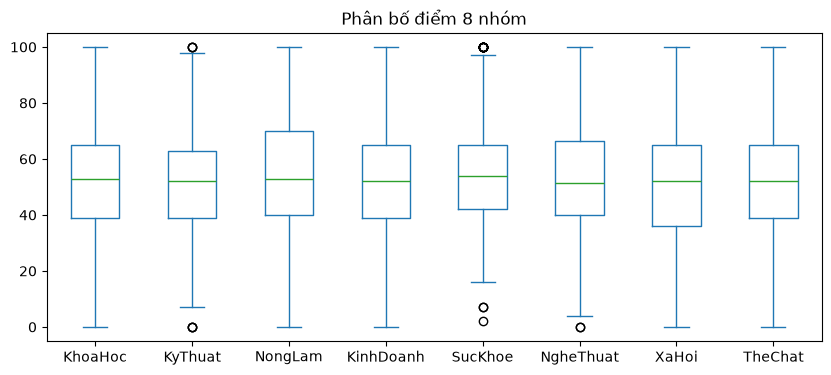

In [3]:
print("Điểm trung bình mỗi nhóm:")
print(hs[NHOM].mean().round(1).to_string())
print("\nSố em theo nhóm có điểm cao nhất:")
print(hs[NHOM].idxmax(axis=1).value_counts().to_string())
hs[NHOM].plot.box(figsize=(10, 4), title="Phân bố điểm 8 nhóm")
plt.show()

## Phần 3 – Phân loại: học máy có hơn quy tắc đơn giản không?

**Baseline** là cách app đang làm: chọn nhóm có điểm cao nhất. Một mô hình chỉ đáng dùng khi thắng được baseline trên những em nó **chưa từng thấy** (tập test).

In [4]:
X, y = hs[NHOM], hs["thich_that"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

cay = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
rung = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_train, y_train)

print(f"Đoán bừa:                       {1/8:.0%}")
print(f"Baseline (nhóm điểm cao nhất):  {accuracy_score(y_test, X_test.idxmax(axis=1)):.0%}")
print(f"Cây quyết định (sâu 3):         {accuracy_score(y_test, cay.predict(X_test)):.0%}")
print(f"Rừng ngẫu nhiên (300 cây):      {accuracy_score(y_test, rung.predict(X_test)):.0%}")

Đoán bừa:                       12%
Baseline (nhóm điểm cao nhất):  63%
Cây quyết định (sâu 3):         37%
Rừng ngẫu nhiên (300 cây):      57%


Cây quyết định đọc được bằng mắt. Mỗi ô là một câu hỏi có/không, đi từ trên xuống.

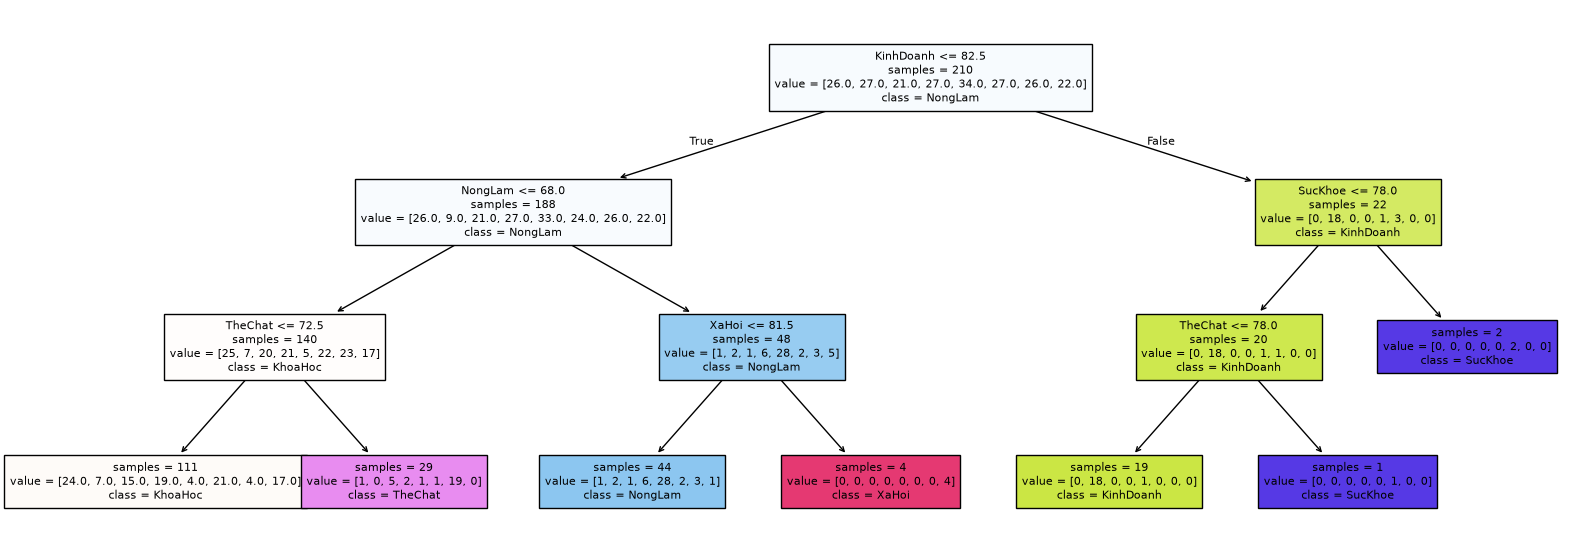

In [5]:
plt.figure(figsize=(20, 7))
plot_tree(cay, feature_names=NHOM, class_names=list(cay.classes_), filled=True, impurity=False, fontsize=8)
plt.show()

## Phần 3b – Độ chắc chắn: so với 10 em giống nhất

Baseline so điểm của em với **một mốc đặt sẵn** (nhóm nào cao nhất). Cách khác: tìm **10 em có điểm giống em này nhất** rồi xem các em đó thích nhóm nào (*k láng giềng gần nhất*, k = 10).

- 7/10 em cùng thích một nhóm → dự đoán **chắc**.
- Chỉ 3/10 → **chưa chắc**, giống nhãn "chưa phân biệt rõ" trong app.

Rừng ngẫu nhiên cũng có ý này: tỷ lệ số cây bỏ phiếu cho một nhóm (`predict_proba`).

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Mỗi em trong tập test: tìm 10 em GIỐNG NHẤT (8 điểm gần nhất) trong tập train, đếm các em đó thích nhóm nào.
lang_gieng = KNeighborsClassifier(n_neighbors=10).fit(X_train, y_train)
phieu = lang_gieng.predict_proba(X_test)                    # tỷ lệ phiếu của 10 em cho từng nhóm
bang = pd.DataFrame({
    "du_doan": lang_gieng.classes_[phieu.argmax(axis=1)],
    "so_phieu": (phieu.max(axis=1) * 10).round().astype(int),  # nhóm nhiều phiếu nhất được mấy/10
    "thich_that": y_test.values,
})
bang["dung"] = bang["du_doan"] == bang["thich_that"]
bang["muc"] = pd.cut(bang["so_phieu"], [0, 4, 6, 10], labels=["≤ 4/10 (chưa chắc)", "5–6/10", "≥ 7/10 (chắc)"])

print(bang.head(5).to_string(index=False))
print()
print(bang.groupby("muc", observed=True).agg(so_em=("dung", "size"), ty_le_dung=("dung", "mean")).round(2).to_string())
print(f"\nĐúng chung (10 em giống nhất): {bang['dung'].mean():.0%}   |   Baseline: {accuracy_score(y_test, X_test.idxmax(axis=1)):.0%}")

  du_doan  so_phieu thich_that  dung                muc
  SucKhoe         8    SucKhoe  True      ≥ 7/10 (chắc)
  NongLam         4      XaHoi False ≤ 4/10 (chưa chắc)
  KyThuat         6    KyThuat  True             5–6/10
NgheThuat         4  NgheThuat  True ≤ 4/10 (chưa chắc)
  NongLam        10    KyThuat False      ≥ 7/10 (chắc)

                    so_em  ty_le_dung
muc                                  
≤ 4/10 (chưa chắc)     39        0.41
5–6/10                 36        0.72
≥ 7/10 (chắc)          15        0.80

Đúng chung (10 em giống nhất): 60%   |   Baseline: 63%


**Đọc kết quả** (lần chạy mẫu: 90 em test):

- Nhóm "≥ 7/10" đúng 80%, nhóm "≤ 4/10" chỉ đúng 41%. Vậy **số phiếu là thước đo độ chắc chắn dùng được**: 7/10 chắc hơn 3/10.
- Nhưng tỷ lệ đúng chung (60%) vẫn **thua baseline** (63%). Vì vậy số phiếu chỉ nên dùng để **gắn cờ "chưa chắc"**, không thay cách xếp nhóm. App đang làm việc tương tự bằng ngưỡng "Nổi bật": hồ sơ không có nhóm nào vượt ngưỡng thì báo "chưa phân biệt rõ".
- Mẫu nhỏ: chỉ 15 em ở nhóm "≥ 7/10", nên các con số này còn dao động nhiều.
- **Ngoài đời không có cột `thich_that`.** "Nhóm em thích" của 10 em giống nhất phải lấy từ nhãn các em **tự chọn trước khi xem kết quả** (đề xuất A2) hoặc nhãn giáo viên. Vì vậy phần này cũng chỉ làm được sau pilot.

## Phần 4 – Ít dữ liệu thì sao? (quá khớp)

Một lớp pilot khoảng 30 em. Cây quyết định không giới hạn độ sâu sẽ học thuộc lòng 30 em đó.

In [7]:
lop = tao_hoc_sinh(30)
em_moi = tao_hoc_sinh(1000)
cay_sau = DecisionTreeClassifier(random_state=0).fit(lop[NHOM], lop["thich_that"])

print(f"Chấm trên chính 30 em đã học:  {accuracy_score(lop['thich_that'], cay_sau.predict(lop[NHOM])):.0%}")
print(f"Chấm trên 1000 em mới:         {accuracy_score(em_moi['thich_that'], cay_sau.predict(em_moi[NHOM])):.0%}")
print(f"Baseline trên 1000 em mới:     {accuracy_score(em_moi['thich_that'], em_moi[NHOM].idxmax(axis=1)):.0%}")

print("\nRừng ngẫu nhiên cần bao nhiêu em để đuổi kịp baseline?")
for n in [30, 100, 300, 1000, 3000]:
    d = tao_hoc_sinh(n)
    m = RandomForestClassifier(n_estimators=200, random_state=0).fit(d[NHOM], d["thich_that"])
    print(f"  học trên {n:>4} em → đúng {accuracy_score(em_moi['thich_that'], m.predict(em_moi[NHOM])):.0%} trên em mới")

Chấm trên chính 30 em đã học:  100%
Chấm trên 1000 em mới:         29%
Baseline trên 1000 em mới:     66%

Rừng ngẫu nhiên cần bao nhiêu em để đuổi kịp baseline?


  học trên   30 em → đúng 42% trên em mới
  học trên  100 em → đúng 56% trên em mới


  học trên  300 em → đúng 62% trên em mới


  học trên 1000 em → đúng 63% trên em mới


  học trên 3000 em → đúng 65% trên em mới


## Phần 5 – Phân cụm k-means (không dùng nhãn)

k-means chỉ nhìn 8 điểm, không nhìn cột `thich_that`. Ta mượn cột đó để kiểm tra xem cụm có trùng với nhóm thích thật không. Ngoài đời thì không kiểm tra được như vậy.
**ARI** đo mức trùng: 0 nghĩa là trùng như ngẫu nhiên, 1 nghĩa là trùng hoàn toàn.

In [8]:
cum = KMeans(n_clusters=8, n_init=10, random_state=0).fit_predict(hs[NHOM])
print("ARI giữa cụm và nhóm thích thật:", round(adjusted_rand_score(hs["thich_that"], cum), 2))
pd.crosstab(pd.Series(cum, name="cụm"), hs["thich_that"])

ARI giữa cụm và nhóm thích thật: 0.24


thich_that,KhoaHoc,KinhDoanh,KyThuat,NgheThuat,NongLam,SucKhoe,TheChat,XaHoi
cụm,,,,,,,,
0,6,29,1,0,3,1,0,2
1,1,0,1,0,3,23,3,0
2,1,2,3,3,26,2,0,0
3,0,0,1,3,3,0,5,16
4,6,0,17,2,3,2,3,5
5,2,1,3,14,2,6,4,0
6,14,1,1,9,2,2,0,9
7,7,5,3,8,6,3,22,0


Cụm có **ổn định** không? Bỏ ngẫu nhiên 10% số em rồi chạy lại, xem những em còn lại có giữ nguyên cụm không. ARI càng gần 1 thì càng ổn định.

In [9]:
def do_on_dinh(d, k, so_lan=20):
    goc = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(d[NHOM])
    ket_qua = []
    for i in range(so_lan):
        giu = rng.choice(len(d), int(len(d) * 0.9), replace=False)
        moi = KMeans(n_clusters=k, n_init=10, random_state=i + 1).fit_predict(d[NHOM].iloc[giu])
        ket_qua.append(adjusted_rand_score(goc[giu], moi))
    return np.mean(ket_qua)

print(f"Bỏ 10% số em rồi chạy lại: ARI trung bình {do_on_dinh(hs, 8):.2f}")

Bỏ 10% số em rồi chạy lại: ARI trung bình 0.35


## Phần 6 – k-means trên dữ liệu bấm bừa

Dữ liệu dưới đây hoàn toàn ngẫu nhiên, không có nhóm nào cả. k-means vẫn chia ra đủ 4 cụm.
**Silhouette** đo cụm tách nhau rõ đến đâu: gần 0 là gần như không tách, gần 1 là tách rất rõ.

In [10]:
bua = pd.DataFrame(rng.uniform(0, 100, (300, 8)), columns=NHOM)
nhan_bua = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(bua)
print("Số em mỗi cụm (dữ liệu bấm bừa):", np.bincount(nhan_bua))
print("Silhouette dữ liệu bấm bừa:     ", round(silhouette_score(bua, nhan_bua), 2))
print("Silhouette dữ liệu giả lập (k=8):", round(silhouette_score(hs[NHOM], cum), 2))

Số em mỗi cụm (dữ liệu bấm bừa): [84 80 77 59]
Silhouette dữ liệu bấm bừa:      0.1
Silhouette dữ liệu giả lập (k=8): 0.1


## Câu hỏi thử thách (bài về nhà)

1. Xóa cột `thich_that`, giống như dữ liệu thật. Phần nào trong notebook còn chạy được, phần nào hết chạy? Vì sao?
2. Sửa `DO_RO = 32` thành `DO_RO = 10` (em thích không rõ ràng) rồi *Run all*. Baseline, rừng ngẫu nhiên và ARI thay đổi ra sao?
3. Viết 3 câu giải thích cho một giáo viên không biết DS: vì sao app chưa dùng mô hình phân loại.
4. Ở Phần 3b, đổi `n_neighbors=10` thành 3 rồi 30. Nhóm "≥ 7/10" còn đúng nhiều hơn nhóm "≤ 4/10" không? Tỷ lệ đúng chung có vượt baseline không?